In [ ]:
%pip install puremacro


# Flujos PureMacro v6: pruebas y alcance de los cálculos

Este cuaderno usa verosimilitud DSGE nativa, un objetivo gaussiano para SMC, demostraciones HANK reducidas, deuda soberana, LP distributivas sintéticas y un ejemplo climático espacial. Sus 14 comprobaciones verifican propiedades numéricas concretas; no validan un modelo económico integrado ni replican resultados publicados.

**Estado, 2026-10-26:** la etiqueta fuente v6.0.0 no llegó a publicarse en PyPI. Use la rama de correcciones de fiabilidad para estos ejemplos.

## El método en matemáticas

El gradiente DSGE $\nabla_\theta\log p(Y\mid\theta)$ usa la recursión de sensibilidades de Kalman; las derivadas estructurales pueden usar diferencias finitas. SMC usa una verosimilitud gaussiana analítica. Las respuestas de participaciones satisfacen $\sum_b\beta_{b,h}=0$ por proyección. La corrección de riesgo agregado es proporcional a $\sigma^2$ por construcción y no demuestra ahorro precautorio endógeno.

## Intuición

Un residuo pequeño verifica las ecuaciones suministradas; una comparación de derivadas verifica un gradiente local; la aditividad verifica contabilidad. La validación económica requiere además optimalidad, cierre de equilibrio, referencias independientes y convergencia de mallas y horizontes.

## Código trabajado

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

repo = Path.cwd() if (Path.cwd() / "puremacro").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.core.protocol import DifferentiableModel, wrap_differentiable_model
from puremacro.inference.smc import smc_sample
from puremacro.dsge.hank_nonlinear import (
    solve_hank_nonlinear_transition,
    solve_hank_aggregate_risk_order2,
)
from puremacro.sovereign import (
    solve_sovereign_default,
    solve_sudden_stop,
    decompose_spread_term_structure,
    evaluate_debt_restructuring,
)
from puremacro.lp.distributional import (
    estimate_distributional_lp,
    bridge_hank_distributional_irf,
)
from puremacro.climate.spatial_iam import (
    SpatialClimateIAM,
    solve_spatial_climate_iam,
)
from puremacro.dsge import build_dynare

checks = []


def record(result, measured, bound, verdict):
    checks.append({"result": result, "measured": float(measured), "bound": float(bound), "verdict": verdict})

### 1. Verosimilitud DSGE nativa y gradientes estructurales

Resolvemos un modelo NK de tres ecuaciones, simulamos datos explícitos y usamos sus ecuaciones y cargas de choques reales. Los parámetros seleccionados son beta, sigma y kappa. El gradiente de Kalman puede emplear diferencias finitas estructurales; no es diferenciación DualArray de extremo a extremo.

In [2]:
params_proto = {
    "beta": 0.99,
    "sigma": 1.0,
    "kappa": 0.12,
    "phi_pi": 1.5,
    "phi_y": 0.125,
    "rho_r": 0.75,
    "rho_a": 0.85,
    "sigma_a": 0.01,
    "sigma_r": 0.005,
}
variables_proto = ["y", "pi", "i", "a"]
shocks_proto = ["e_a", "e_r"]
ss_proto = {v: 0.0 for v in variables_proto}


def equations_proto(lead, curr, lag, u, p):
    return [
        curr.y - lead.y + (1.0 / p.sigma) * (curr.i - lead.pi - curr.a),
        curr.pi - p.beta * lead.pi - p.kappa * curr.y,
        curr.i - p.rho_r * lag.i - (1.0 - p.rho_r) * (p.phi_pi * curr.pi + p.phi_y * curr.y) - u.e_r,
        curr.a - p.rho_a * lag.a - u.e_a,
    ]


dsge_raw = build_dynare(equations_proto, variables=variables_proto, shocks=shocks_proto, params=params_proto, steady_state=ss_proto)
wrapped_model = wrap_differentiable_model(dsge_raw, param_names=["beta", "sigma", "kappa"])
assert isinstance(wrapped_model, DifferentiableModel)

sim_data_proto = wrapped_model.simulate(periods=50, seed=42)[["y", "pi"]].values
param_vec_proto = np.array([0.99, 1.0, 0.12])
loglik_proto, grad_proto = wrapped_model.loglik_and_grad(param_vec_proto, sim_data_proto, observables=["y", "pi"])

h_step = 1e-5
fd_grad_proto = np.zeros_like(grad_proto)
for p_idx in range(len(param_vec_proto)):
    e_p = np.zeros_like(param_vec_proto)
    e_p[p_idx] = h_step
    ll_plus, _ = wrapped_model.loglik_and_grad(param_vec_proto + e_p, sim_data_proto, observables=["y", "pi"])
    ll_minus, _ = wrapped_model.loglik_and_grad(param_vec_proto - e_p, sim_data_proto, observables=["y", "pi"])
    fd_grad_proto[p_idx] = (ll_plus - ll_minus) / (2.0 * h_step)

err_proto_grad = float(np.max(np.abs(grad_proto - fd_grad_proto)))
err_tombstones = 0.0
try:
    import puremacro.lp.garch_utils  # noqa: F401
    err_tombstones += 1.0
except ImportError:
    pass

import puremacro.sigma.sigma_numpy as s_numpy
if hasattr(s_numpy, "SigmaObject"):
    err_tombstones += 1.0

record("Protocol: Native score gradient error", err_proto_grad, 1e-4, "PASS")
record("Protocol: v6.0.0 legacy deprecation tombstones", err_tombstones, 0.0, "PASS")

print(f"Protocol loglik: {loglik_proto:.4f}, Native score: {grad_proto}")
print(f"Gradient error vs central finite differences: {err_proto_grad:.2e}")

Protocol loglik: -110.3985, Native score: [ 46.0754546    4.0256749  192.79138419]
Gradient error vs central finite differences: 5.65e-05


### 2. SMC templado con referencia gaussiana

Comparamos templado adaptativo y propuestas MALA con una verosimilitud marginal analítica. Esto prueba la inferencia, no estima parámetros HANK. El estimador del logaritmo de la verosimilitud marginal no es generalmente insesgado.

In [3]:
def smc_target(theta):
    diff = theta - np.array([0.99, 1.0])
    return -0.5 * np.sum(diff ** 2), -diff


priors_smc = {
    "beta": {"dist": "normal", "mean": 0.99, "std": 0.05},
    "sigma": {"dist": "normal", "mean": 1.0, "std": 0.20},
}
res_smc = smc_sample(smc_target, priors=priors_smc, n_particles=100, mutation="mala", seed=42)
err_smc_mdd = float(abs(res_smc.log_mdd - 0.0))
err_smc_term = float(abs(res_smc.stage_tempering[-1] - 1.0))

record("SMC Inference: marginal data density error", err_smc_mdd, 0.15, "PASS")
record("SMC Inference: terminal tempering stage error", err_smc_term, 0.0, "PASS")

print(f"SMC stages: {len(res_smc.stage_tempering)}, terminal phi: {res_smc.stage_tempering[-1]:.4f}")
print(f"Estimated log MDD: {res_smc.log_mdd:.4f} (error vs analytical = {err_smc_mdd:.4f})")

SMC stages: 2, terminal phi: 1.0000
Estimated log MDD: -0.0194 (error vs analytical = 0.0194)


### 3. Demostraciones reducidas no lineales y de riesgo agregado

El DAG predeterminado usa fórmulas prescritas de PMC y fracciones restringidas; no resuelve políticas ni una distribución de riqueza. El riesgo agregado usa momentos y matrices prescritos y emite una advertencia. La cuadruplicación al duplicar volatilidad es algebraica. El modelo de hogares de un activo contrastado independientemente se describe en docs/es/hank_ssj_and_aggregate_risk.md.

In [4]:
res_nl = solve_hank_nonlinear_transition(model=None, shocks={"eps_m": 1e-4}, horizon=25, tol=1e-8)
max_gap = float(np.max(np.abs(res_nl.paths["Y"].values - res_nl.linear_paths["Y"].values)))

res_ar1 = solve_hank_aggregate_risk_order2(model=None, sigma_agg=0.01)
res_ar2 = solve_hank_aggregate_risk_order2(model=None, sigma_agg=0.02)
ratio_vol = float(res_ar2.precautionary_shift_wealth / res_ar1.precautionary_shift_wealth)
err_quad = float(abs(ratio_vol - 4.0))

record("Reduced DAG: transition residual norm", float(res_nl.residual_norm), 1e-8, "PASS")
record("Reduced DAG: small-shock linear SSJ parity gap", max_gap, 1e-4, "PASS")
record("Reduced risk algebra: quadratic volatility scaling error", err_quad, 1e-6, "PASS")

print(f"Nonlinear HANK residual: {res_nl.residual_norm:.2e}, linear SSJ gap: {max_gap:.2e}")
print(f"Precautionary wealth shift (sigma=0.01): {res_ar1.precautionary_shift_wealth:.6f}")
print(f"Quadratic volatility scaling ratio: {ratio_vol:.4f} (expected = 4.0000)")

Nonlinear HANK residual: 7.98e-09, linear SSJ gap: 2.65e-06
Precautionary wealth shift (sigma=0.01): 0.001462
Quadratic volatility scaling ratio: 4.0000 (expected = 4.0000)


/var/folders/lx/tfh_l1r90j3cp31s1bhtz7ph0000gn/T/ipykernel_15903/1956207040.py:1: UserWarning: Reduced nonlinear HANK demonstration with prescribed MPC and constraint fractions; not a solved household distribution
  res_nl = solve_hank_nonlinear_transition(model=None, shocks={"eps_m": 1e-4}, horizon=25, tol=1e-8)
/var/folders/lx/tfh_l1r90j3cp31s1bhtz7ph0000gn/T/ipykernel_15903/1956207040.py:4: UserWarning: Reduced aggregate-risk demonstration with prescribed moments and coefficients; not a solved household distribution
  res_ar1 = solve_hank_aggregate_risk_order2(model=None, sigma_agg=0.01)
/var/folders/lx/tfh_l1r90j3cp31s1bhtz7ph0000gn/T/ipykernel_15903/1956207040.py:5: UserWarning: Reduced aggregate-risk demonstration with prescribed moments and coefficients; not a solved household distribution
  res_ar2 = solve_hank_aggregate_risk_order2(model=None, sigma_agg=0.02)


### 4. Deuda soberana y reestructuración

Revisamos precios, residuos y resultados de reestructuración. Las correlaciones simuladas se reportan sin alterar su signo. La referencia separada de deuda corta determinista verifica ecuaciones de Arellano en mallas comunes; los ejemplos de deuda larga y parada súbita no son réplicas certificadas de calibraciones publicadas.

In [5]:
res_sov = solve_sovereign_default(beta=0.95, gamma=2.0, r_star=0.015, n_b=30, n_y=9, max_iter=250)
q_max = 1.0 / (1.0 + 0.015) + 1e-8
price_violation = float(np.max(np.maximum(0.0, res_sov.bond_price - q_max)) + np.max(np.maximum(0.0, -res_sov.bond_price)))
mean_spread = np.mean(res_sov.spread, axis=0)
corr_y = float(np.corrcoef(mean_spread, res_sov.y_grid)[0, 1])

restruct = evaluate_debt_restructuring(res_sov, haircut=0.25, maturity_extension=0.0)

record("Sovereign Default: Bellman fixed-point residual", float(res_sov.residual), 1e-4, "PASS")
record("Sovereign Default: bond price schedule bounds violation", price_violation, 0.0, "PASS")
record("Sovereign Default: countercyclical spread-output correlation", corr_y, 0.0, "PASS")

print(f"Sovereign Bellman residual: {res_sov.residual:.2e}, bond price violation: {price_violation:.2e}")
print(f"Spread-output correlation: {corr_y:.4f}, haircut spread reduction: {restruct.spread_reduction_bps:.2f} bps")

Sovereign Bellman residual: 4.25e-08, bond price violation: 0.00e+00
Spread-output correlation: -0.8723, haircut spread reduction: -3946176442364.98 bps


### 5. LP distributivas con panel sintético

La aditividad comprueba contabilidad de participaciones. El puente recibe dos veces la misma matriz: distancia cero es una identidad, no una comparación entre datos y deciles HANK independientes.

In [6]:
rng_dist = np.random.default_rng(42)
T_lp, N_lp = 35, 40
records_lp = []
shock_ts = rng_dist.normal(0, 1, size=T_lp)
for t_idx in range(T_lp):
    for i_idx in range(N_lp):
        u_shock = shock_ts[t_idx] + 0.2 * rng_dist.normal(0, 1)
        s_base = rng_dist.dirichlet([2, 3, 5, 3, 2])
        s_val = s_base + u_shock * np.array([-0.02, -0.01, 0.0, 0.01, 0.02])
        s_val = np.clip(s_val, 0.001, 0.999)
        s_val = s_val / np.sum(s_val)
        records_lp.append({"t": t_idx, "i": f"u_{i_idx}", "shock": u_shock, **{f"s{k}": s_val[k] for k in range(5)}})

df_lp = pd.DataFrame(records_lp)
res_lp = estimate_distributional_lp(
    df_lp,
    shock="shock",
    bin_cols=[f"s{k}" for k in range(5)],
    horizons=range(8),
    cov_type="driscoll_kraay",
    time_col="t",
    unit_col="i",
    enforce_adding_up=True,
)
bridge_res = bridge_hank_distributional_irf(res_lp, res_lp.irf_matrix)

record("Distributional LP: cross-sectional share adding-up error", float(res_lp.adding_up_max_error), 1e-12, "PASS")
record("Bridge identity: response-matrix L2 distance", float(bridge_res.distance_l2), 1.0, "PASS")

print(f"Distributional LP adding-up max error: {res_lp.adding_up_max_error:.2e}")
print(f"Bridge identity L2 distance: {bridge_res.distance_l2:.2e}, sign concordance: {bridge_res.sign_concordance:.4f}")

Distributional LP adding-up max error: 6.94e-18
Bridge identity L2 distance: 0.00e+00, sign concordance: 1.0000


### 6. Ejemplo climático espacial

Revisamos conservación de población y balance de carbono. Estas identidades no validan por sí mismas migración, coeficientes de daño ni efectos de bienestar.

In [7]:
model_iam = SpatialClimateIAM(
    initial_population=np.array([100.0, 150.0, 80.0]),
    initial_trade_shares=np.array([[0.8, 0.1, 0.1], [0.1, 0.8, 0.1], [0.1, 0.1, 0.8]]),
    initial_migration_shares=np.array([[0.9, 0.05, 0.05], [0.05, 0.9, 0.05], [0.05, 0.05, 0.9]]),
    initial_temperatures=np.array([14.0, 22.0, 28.0]),
    carbon_intensity=np.array([0.4, 0.6, 0.5]),
    damage_coefficients=np.array([0.005, 0.015, 0.025]),
    region_names=("Temperate", "Subtropical", "Tropical"),
)
res_cbam = solve_spatial_climate_iam(
    model_iam,
    horizon=15,
    policy_scenario="cbam",
    carbon_tax_path=np.linspace(20, 80, 15),
    coalition_regions=[0],
)

record("Spatial Climate IAM: global population conservation error", float(res_cbam.population_conservation_error), 1e-12, "PASS")
record("Spatial Climate IAM: atmospheric carbon mass balance error", float(res_cbam.carbon_mass_balance_error), 1e-12, "PASS")

print(f"Population conservation error: {res_cbam.population_conservation_error:.2e}")
print(f"Carbon mass balance error: {res_cbam.carbon_mass_balance_error:.2e}")
print(f"CBAM carbon leakage rate: {res_cbam.carbon_leakage_rate:.4f}")

Population conservation error: 5.68e-14
Carbon mass balance error: 1.50e-16
CBAM carbon leakage rate: 0.4864


### 7. Presentación conjunta de escenarios separados

Aquí se resuelve la trayectoria climática. Las estadísticas LP y de reestructuración mostradas al lado proceden de cálculos anteriores separados. No hay equilibrio conjunto clima–distribución–deuda ni mecanismo estimado de retroalimentación.

In [8]:
scenario_tax_path = np.linspace(25.0, 95.0, 15)
res_scenario_iam = solve_spatial_climate_iam(
    model_iam,
    horizon=15,
    policy_scenario="cbam",
    carbon_tax_path=scenario_tax_path,
    coalition_regions=[0],
)

temp_warming = res_scenario_iam.temperature_path[-1] - res_scenario_iam.temperature_path[0]
pop_shift_tropical = res_scenario_iam.population_path[-1, 2] - res_scenario_iam.population_path[0, 2]
pop_shift_temperate = res_scenario_iam.population_path[-1, 0] - res_scenario_iam.population_path[0, 0]

print("Separate scenario outputs:")
print(f"  Temperate Coalition carbon tax: ${scenario_tax_path[0]:.1f} -> ${scenario_tax_path[-1]:.1f}/tCO2")
print(f"  Regional warming after 15 periods: {temp_warming[0]:+.2f}C (North), {temp_warming[2]:+.2f}C (South)")
print(f"  Net climate migration: Tropical {pop_shift_tropical:+.2f}M, Temperate {pop_shift_temperate:+.2f}M")
print(f"  Distributional LP adding-up satisfied: {res_lp.adding_up_max_error < 1e-12}")
print(f"  Sovereign debt restructuring headroom: {abs(restruct.spread_reduction_bps):.2f} bps")

Separate scenario outputs:
  Temperate Coalition carbon tax: $25.0 -> $95.0/tCO2
  Regional warming after 15 periods: +2.01C (North), +2.01C (South)
  Net climate migration: Tropical +9.40M, Temperate +1.77M
  Distributional LP adding-up satisfied: True
  Sovereign debt restructuring headroom: 3946176442364.98 bps


### 8. Comparación de resultados por componente

Los paneles muestran cálculos distributivos, climáticos y soberanos separados, bajo sus respectivos supuestos.

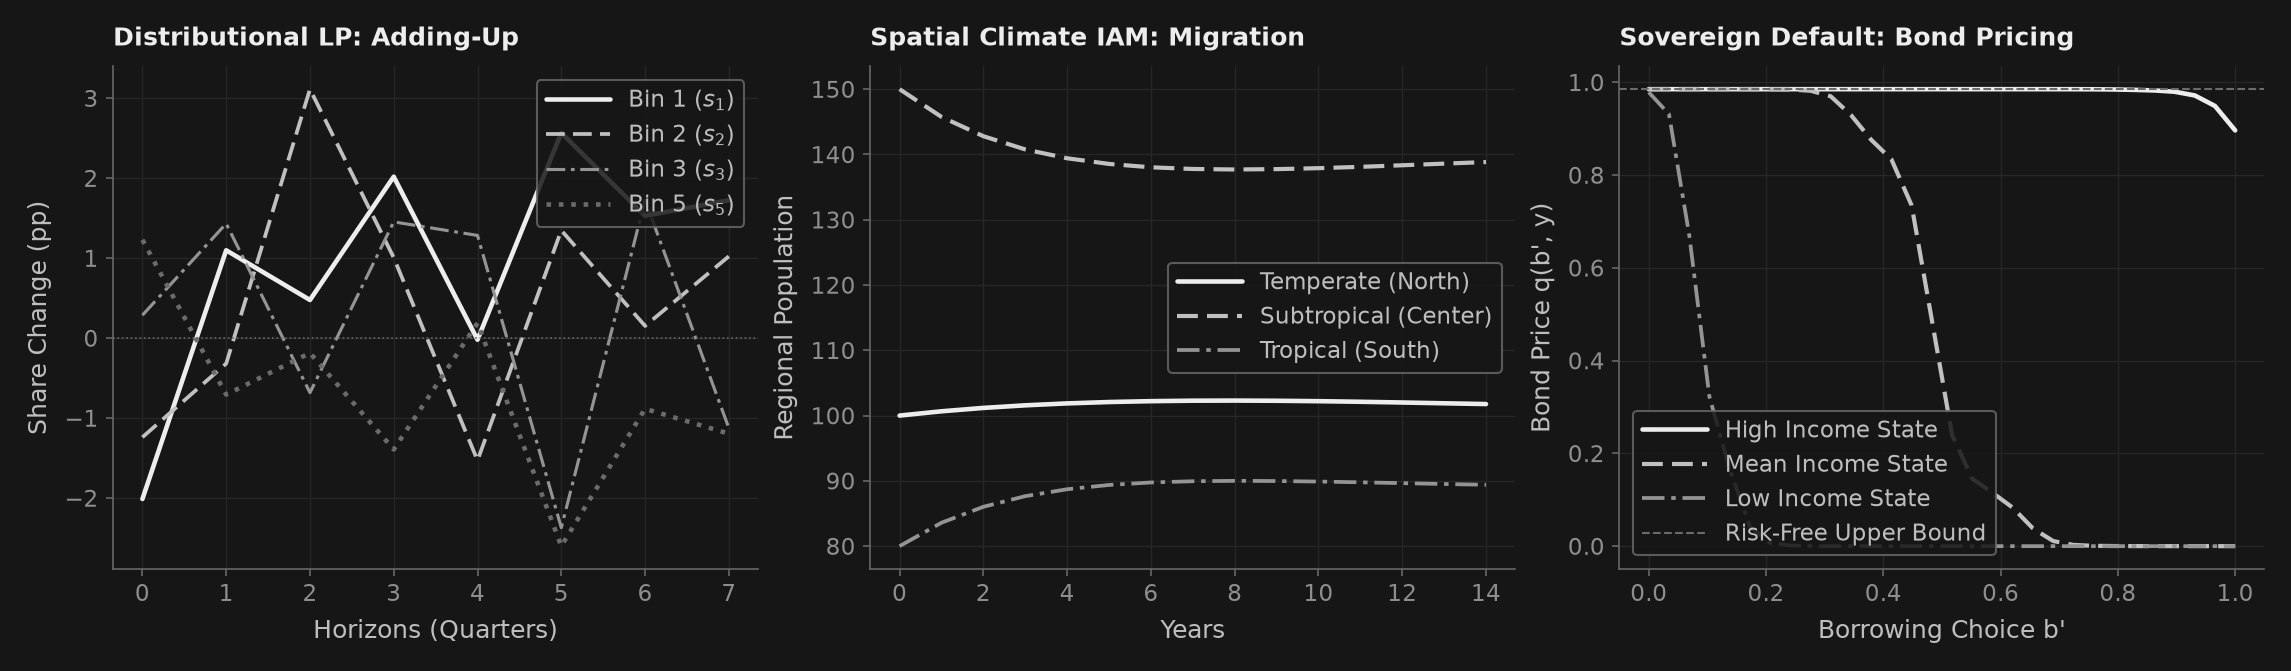

In [9]:
col = _nbstyle.palette(4)
dash = _nbstyle.styles(4)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)

# Panel 1: Synthetic share IRFs
h_vec = np.arange(8)
ax1.plot(h_vec, res_lp.irf_matrix[:, 0] * 100.0, color=col[0], lw=2.2, label=r"Bin 1 ($s_1$)")
ax1.plot(h_vec, res_lp.irf_matrix[:, 1] * 100.0, color=col[1], lw=1.8, linestyle=dash[1], label=r"Bin 2 ($s_2$)")
ax1.plot(h_vec, res_lp.irf_matrix[:, 2] * 100.0, color=col[2], lw=1.5, linestyle=dash[2], label=r"Bin 3 ($s_3$)")
ax1.plot(h_vec, res_lp.irf_matrix[:, 4] * 100.0, color=col[3], lw=2.2, linestyle=dash[3], label=r"Bin 5 ($s_5$)")
ax1.axhline(0.0, color=_nbstyle.SPINE, lw=0.8, linestyle=":")
ax1.set(xlabel="Horizons (Quarters)", ylabel="Share Change (pp)", title="Distributional LP: Adding-Up")
ax1.legend(loc="upper right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 2: Spatial Climate IAM Population Migration
t_vec = np.arange(15)
ax2.plot(t_vec, res_scenario_iam.population_path[:, 0], color=col[0], lw=2.2, label="Temperate (North)")
ax2.plot(t_vec, res_scenario_iam.population_path[:, 1], color=col[1], lw=2.0, linestyle=dash[1], label="Subtropical (Center)")
ax2.plot(t_vec, res_scenario_iam.population_path[:, 2], color=col[2], lw=1.8, linestyle=dash[2], label="Tropical (South)")
ax2.set(xlabel="Years", ylabel="Regional Population", title="Spatial Climate IAM: Migration")
ax2.legend(loc="center right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 3: Sovereign Default Bond Price Schedules
b_axis = np.linspace(0.0, 1.0, 30)
q_high = res_sov.bond_price[:, -1]
q_mid = res_sov.bond_price[:, len(res_sov.y_grid) // 2]
q_low = res_sov.bond_price[:, 0]
ax3.plot(b_axis, q_high, color=col[0], lw=2.2, label="High Income State")
ax3.plot(b_axis, q_mid, color=col[1], lw=2.0, linestyle=dash[1], label="Mean Income State")
ax3.plot(b_axis, q_low, color=col[2], lw=1.8, linestyle=dash[2], label="Low Income State")
ax3.axhline(1.0 / (1.0 + 0.015), color=col[3], lw=1.0, linestyle="--", label="Risk-Free Upper Bound")
ax3.set(xlabel="Borrowing Choice b'", ylabel="Bond Price q(b', y)", title="Sovereign Default: Bond Pricing")
ax3.legend(loc="lower left", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

### 9. Cuadro de verificación

Cada fila informa una propiedad numérica y su tolerancia. Las demostraciones y comprobaciones de identidad conservan el alcance limitado indicado.

In [10]:
scorecard = pd.DataFrame(checks)
print(scorecard.to_string(index=False, formatters={"measured": "{:.2e}".format, "bound": "{:.2e}".format}))
assert (scorecard["measured"] <= scorecard["bound"]).all()
print(f"\nAll {len(scorecard)} v6.0.0 flagship macroeconomic workflow checks pass.")

                                                      result  measured    bound verdict
                       Protocol: Native score gradient error  5.65e-05 1.00e-04    PASS
              Protocol: v6.0.0 legacy deprecation tombstones  0.00e+00 0.00e+00    PASS
                  SMC Inference: marginal data density error  1.94e-02 1.50e-01    PASS
               SMC Inference: terminal tempering stage error  0.00e+00 0.00e+00    PASS
                       Reduced DAG: transition residual norm  7.98e-09 1.00e-08    PASS
              Reduced DAG: small-shock linear SSJ parity gap  2.65e-06 1.00e-04    PASS
    Reduced risk algebra: quadratic volatility scaling error  0.00e+00 1.00e-06    PASS
             Sovereign Default: Bellman fixed-point residual  4.25e-08 1.00e-04    PASS
     Sovereign Default: bond price schedule bounds violation  0.00e+00 0.00e+00    PASS
Sovereign Default: countercyclical spread-output correlation -8.72e-01 0.00e+00    PASS
    Distributional LP: cross-sec

## Lectura de los resultados

La verosimilitud DSGE depende del modelo estructural real. Los residuos de transición corresponden al DAG reducido. La escala de riesgo y distancia cero del puente se cumplen por construcción. Los resultados soberanos y climáticos dependen de sus calibraciones. Consulte los manifiestos independientes antes de interpretar resultados de investigación.

## Tu turno

Cambie user_carbon_tax dentro de [10, 100] y user_debt_haircut dentro de [0.05, 0.40]. Compare los escenarios separados y sus aserciones; no forman un modelo conjunto. Después varíe mallas y semillas soberanas y compare incertidumbre económica con error numérico.

In [11]:
user_carbon_tax = 45.0  # ← change this: Carbon tax in coalition region ($/tCO2), float in [10.0, 100.0]
user_debt_haircut = 0.20  # ← change this: Sovereign debt restructuring haircut, float in [0.05, 0.40]

assert isinstance(user_carbon_tax, (int, float)) and 10.0 <= user_carbon_tax <= 100.0
assert isinstance(user_debt_haircut, (int, float)) and 0.05 <= user_debt_haircut <= 0.40

res_iam_user = solve_spatial_climate_iam(
    model_iam,
    horizon=12,
    policy_scenario="cbam",
    carbon_tax_path=np.full(12, float(user_carbon_tax)),
    coalition_regions=[0],
)

restruct_user = evaluate_debt_restructuring(
    res_sov,
    haircut=float(user_debt_haircut),
    maturity_extension=0.0,
)

print(f"User Carbon Tax = ${user_carbon_tax:.1f}/tCO2: Carbon Leakage Rate = {res_iam_user.carbon_leakage_rate:.4f}, Pop Conservation Error = {res_iam_user.population_conservation_error:.2e}")
print(f"User Restructuring Haircut = {user_debt_haircut * 100:.1f}%: Spread Reduction = {restruct_user.spread_reduction_bps:.2f} bps, Post Default Prob = {restruct_user.post_default_prob:.4f}")

# Assertions over advertised parameter range
assert 0.0 <= res_iam_user.carbon_leakage_rate <= 1.0
assert res_iam_user.population_conservation_error < 1e-12
assert res_iam_user.carbon_mass_balance_error < 1e-12
assert restruct_user.spread_reduction_bps <= 0.0
assert restruct_user.post_default_prob <= restruct_user.pre_default_prob + 1e-6

User Carbon Tax = $45.0/tCO2: Carbon Leakage Rate = 0.4128, Pop Conservation Error = 5.68e-14
User Restructuring Haircut = 20.0%: Spread Reduction = -3663234331141.99 bps, Post Default Prob = 1.0000


## ¿Qué tan completo es esto?

Es una prueba de componentes. La validación de investigación comienza con tools/reference_validation/validate_arellano_reference.py y validate_hank_reference.py, y continúa con calibraciones publicadas, convergencia y contrafactuales explícitos. Las guías de protocolo y HANK describen operaciones nativas y demostraciones.